In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported Sucessfully!")

Libraries imported Sucessfully!


In [3]:
#Load Libraries
df=pd.read_csv(r"C:\Users\VISHNU\Downloads\Internship\Dataset\Day4\DATA\Netflix_cleaned.csv")
df.head()
print("Dataset Shape:", df.shape)
df.columns.tolist()

df.info()

Dataset Shape: (8790, 10)
<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 1.8 MB


In [6]:
#Check Release year of the column
#Convert release year into numeric format

df["release_year"] = pd.to_numeric(
    df["release_year"],
    errors="coerce"
)

#Remove rows without valid release years

df = df.dropna(subset=["release_year"]).copy()

#Convert to integer
df["release_year"]= df["release_year"].astype(int)

#Remove invalid or future years

df = df[
    df["release_year"].between(
        1900,pd.Timestamp.today().year
    )
].copy()

print("Cleaned Dataset:", df.shape)

Cleaned Dataset: (8790, 10)


In [7]:
#check release year range

print("Earliest Release year:", df["release_year"].min())
print("Latest Release year:", df["release_year"].max())
print("Unique Release Year:", df["release_year"].nunique())

Earliest Release year: 1925
Latest Release year: 2021
Unique Release Year: 74


In [8]:
#sort date by release year

df = df.sort_values(
    by="release_year",
    ascending=True
)

print(
    df[["title", "release_year"]].head(20)
)

                                                 title  release_year
421                  Pioneers: First Women Filmmakers*          1925
6037                              The Battle of Midway          1942
5698                                    Prelude to War          1942
6422     Undercover: How to Operate Behind Enemy Lines          1943
6510                   WWII: Report from the Aleutians          1943
6491                Why We Fight: The Battle of Russia          1943
6406                                  Tunisian Victory          1944
6218  The Memphis Belle: A Story of a\nFlying Fortress          1944
6230                                 The Negro Soldier          1944
5545                          Nazi Concentration Camps          1945
5264                           Know Your Enemy - Japan          1945
6874               Five Came Back: The Reference Films          1945
5812                                        San Pietro          1945
5320                              

In [9]:
#Step 2 Caluclate yearly content release

#count titles by  year

yearly_content = (
    df.groupby("release_year")["show_id"]
    .nunique()
    .reset_index(name="Total_Content")
)

print(yearly_content.tail(20))

    release_year  Total_Content
54          2002             51
55          2003             59
56          2004             64
57          2005             80
58          2006             96
59          2007             88
60          2008            135
61          2009            152
62          2010            192
63          2011            185
64          2012            236
65          2013            286
66          2014            352
67          2015            555
68          2016            901
69          2017           1030
70          2018           1146
71          2019           1030
72          2020            953
73          2021            592


In [11]:
#Caluclate yearly Movie and Tv Show count

yearly_type = (
    df.groupby(["release_year", "type"])["show_id"]
    .nunique()
    .unstack(fill_value=0)
)

print(yearly_type.tail(20))



type          Movie  Tv Show
release_year                
2002             44        7
2003             51        8
2004             55        9
2005             67       13
2006             82       14
2007             74       14
2008            113       22
2009            118       34
2010            153       39
2011            145       40
2012            173       63
2013            225       61
2014            264       88
2015            396      159
2016            658      243
2017            765      265
2018            767      379
2019            633      397
2020            517      436
2021            277      315


In [12]:
#identify the year with the most content

peak_year = yearly_content.loc[
    yearly_content["Total_Content"].idxmax()
]

print("Peak Release Year:", int(peak_year["release_year"]))

Peak Release Year: 2018


In [14]:
#Identify the top 10 release years
top_10_years =  yearly_content.nlargest(
    10,
    "Total_Content"
)

print(top_10_years)

    release_year  Total_Content
70          2018           1146
69          2017           1030
71          2019           1030
72          2020            953
68          2016            901
73          2021            592
67          2015            555
66          2014            352
65          2013            286
64          2012            236


In [15]:
#Step 3 – Identify growth and decline trends

#Calculate year-over-year growth

yearly_content = yearly_content.sort_values(
    "release_year"
).copy()

yearly_content["Previous_Year_Content"] = (
    yearly_content["Total_Content"].shift(1)
)

yearly_content["YoY_Growth_Percentage"] = (
    yearly_content["Total_Content"].pct_change() * 100
)

print(yearly_content.tail(20))

    release_year  Total_Content  Previous_Year_Content  YoY_Growth_Percentage
54          2002             51                   45.0              13.333333
55          2003             59                   51.0              15.686275
56          2004             64                   59.0               8.474576
57          2005             80                   64.0              25.000000
58          2006             96                   80.0              20.000000
59          2007             88                   96.0              -8.333333
60          2008            135                   88.0              53.409091
61          2009            152                  135.0              12.592593
62          2010            192                  152.0              26.315789
63          2011            185                  192.0              -3.645833
64          2012            236                  185.0              27.567568
65          2013            286                  236.0          

In [16]:
#Identify growth and decline years

yearly_content["Trend"] = np.select(
    [
        yearly_content["YoY_Growth_Percentage"] > 0,
        yearly_content["YoY_Growth_Percentage"] < 0,
        yearly_content["YoY_Growth_Percentage"] == 0
    ],
    [
        "Growth",
        "Decline",
        "No Change"
    ],
    default="N/A"
)

print(
    yearly_content[
        [
            "release_year",
            "Total_Content",
            "YoY_Growth_Percentage",
            "Trend"
        ]
    ].tail(20)
)

    release_year  Total_Content  YoY_Growth_Percentage    Trend
54          2002             51              13.333333   Growth
55          2003             59              15.686275   Growth
56          2004             64               8.474576   Growth
57          2005             80              25.000000   Growth
58          2006             96              20.000000   Growth
59          2007             88              -8.333333  Decline
60          2008            135              53.409091   Growth
61          2009            152              12.592593   Growth
62          2010            192              26.315789   Growth
63          2011            185              -3.645833  Decline
64          2012            236              27.567568   Growth
65          2013            286              21.186441   Growth
66          2014            352              23.076923   Growth
67          2015            555              57.670455   Growth
68          2016            901         

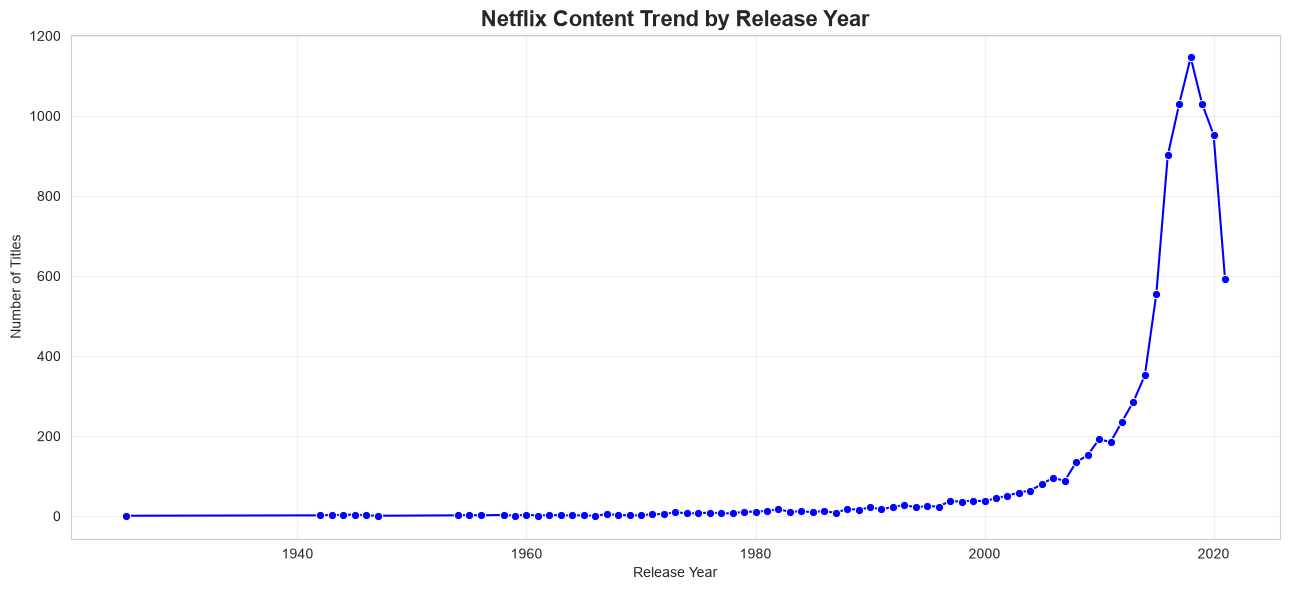

In [18]:
#Step 4 – Create trend visualizations
#Yearly Netflix content trend

plt.figure(figsize=(13,6))

sns.lineplot(
    data=yearly_content,
    x="release_year",
    y="Total_Content",
    marker="o",
    color="blue"
)

plt.title(
    "Netflix Content Trend by Release Year",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

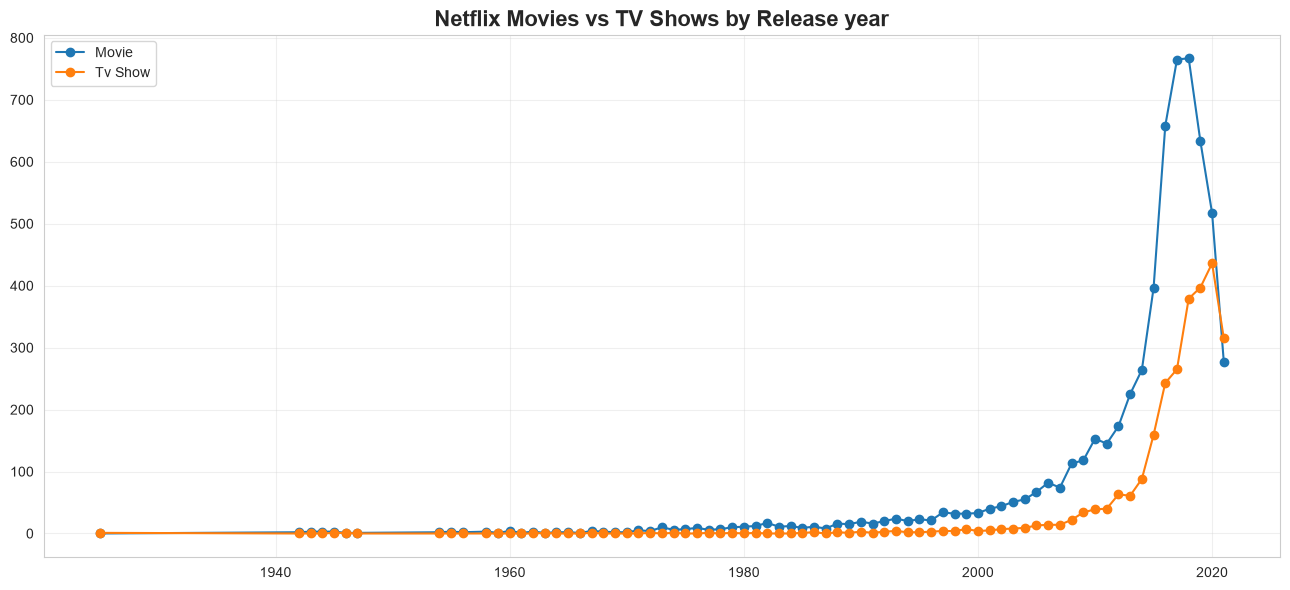

In [19]:
#Movies vs TV Shows over time
plt.figure(figsize=(13,6))

for content_type in yearly_type.columns:
    plt.plot(
        yearly_type.index,
        yearly_type[content_type],
        marker="o",
        label=content_type
    )
    
    
plt.title(
    "Netflix Movies vs TV Shows by Release year",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.legend()
plt.grid(True,alpha=0.3)

plt.tight_layout()
plt.savefig("Movies_vs_TvShows_Trend.png",dpi=300)
plt.show()

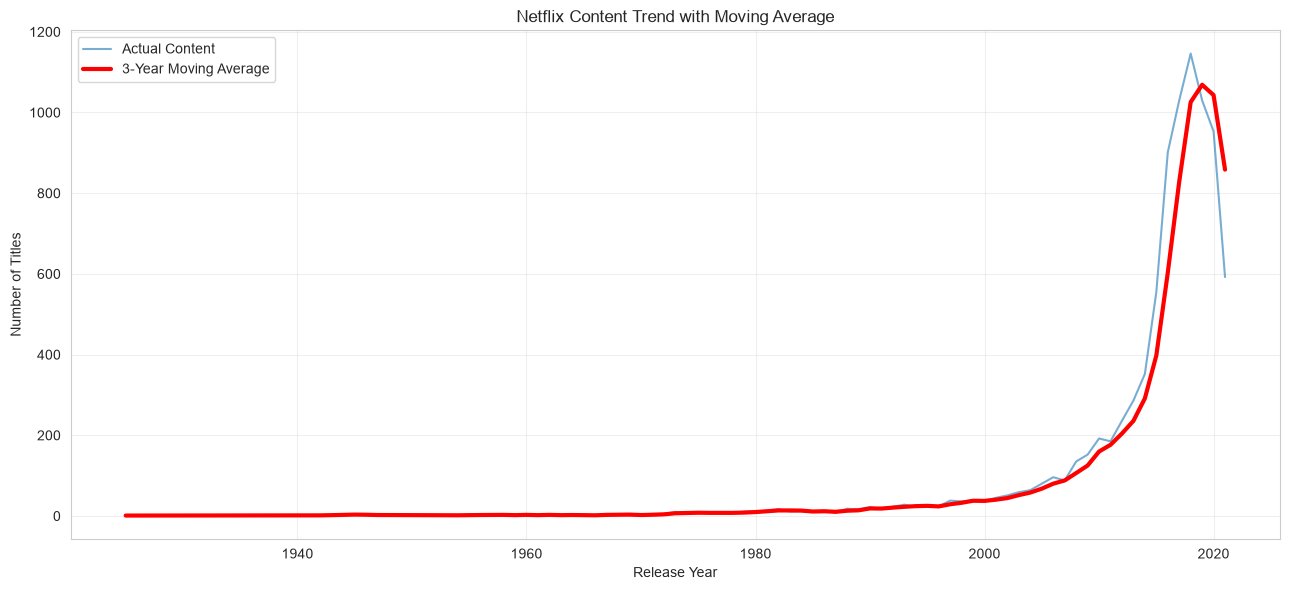

In [27]:
yearly_content["Moving_Average_3Y"] = (
    yearly_content["Total_Content"].rolling(window=3, min_periods=1).mean()
)

plt.figure(figsize=(13, 6))

plt.plot(
    yearly_content["release_year"],
    yearly_content["Total_Content"],
    label="Actual Content",
    alpha=0.6
)

plt.plot(
    yearly_content["release_year"],
    yearly_content["Moving_Average_3Y"],
    label="3-Year Moving Average",
    linewidth=3,
    color="red"
)

plt.title("Netflix Content Trend with Moving Average")

ax = plt.gca()
ax.set_xlabel("Release Year")
ax.set_ylabel("Number of Titles")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("Netflix_Moving_Average.png", dpi=300)
plt.show()

In [29]:
#Interpret business patterns
print("========== NETFLIX TREND INSIGHTS ==========")

growth_rates = yearly_content.dropna(subset=["YoY_Growth_Percentage"])
highest_growth = growth_rates.loc[
    growth_rates["YoY_Growth_Percentage"].idxmax()
]
highest_decline = growth_rates.loc[
    growth_rates["YoY_Growth_Percentage"].idxmin()
]

print(
    f"1. Total unique titles: "
    f"{df['show_id'].nunique():,}"
)

print(
    f"2. Earliest release year: "
    f"{df['release_year'].min()}"
)

print(
    f"3. Latest release year: "
    f"{df['release_year'].max()}"
)

print(
    f"4. Peak content year: "
    f"{int(peak_year['release_year'])}"
)

print(
    f"5. Titles in peak year: "
    f"{int(peak_year['Total_Content']):,}"
)

print(
    f"6. Highest growth year: "
    f"{int(highest_growth['release_year'])}"
)

print(
    f"7. Highest decline year: "
    f"{int(highest_decline['release_year'])}"
)

print(
    f"8. Total growth years: "
    f"{(yearly_content['Trend'] == 'Growth').sum()}"
)

print(
    f"9. Total decline years: "
    f"{(yearly_content['Trend'] == 'Decline').sum()}"
)

========== NETFLIX TREND INSIGHTS ==========
1. Total unique titles: 8,790
2. Earliest release year: 1925
3. Latest release year: 2021
4. Peak content year: 2018
5. Titles in peak year: 1,146
6. Highest growth year: 1967
7. Highest decline year: 1961
8. Total growth years: 40
9. Total decline years: 25


In [30]:
#Export the analysis
# Export yearly content counts and growth
yearly_content.to_csv(
    "Netflix_Yearly_Trend_Analysis.csv",
    index=False
)

# Export Movie vs TV Show trends
yearly_type.to_csv(
    "Netflix_Movie_TV_Yearly_Trend.csv"
)

# Export top 10 release years
top_10_years.to_csv(
    "Netflix_Top_10_Release_Years.csv",
    index=False
)

print("All CSV files exported successfully!")

All CSV files exported successfully!
